In [2]:
#Data Manipulation
import pandas as pd
import numpy as np

#Regular expression for text cleaning
import re

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

#Tensorflow / Keras for the LSTM
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

#Evaluating the classification model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [3]:
#For analyzing word frequencies
from collections import Counter

#Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

In [4]:
df = pd.read_csv("tweet_emotions.csv")

In [5]:
df.head()

,tweet_id,sentiment,content
0,1956967341,empty,@tiffanylue i know i was listenin to bad habit earlier and i started freakin at his part =[
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin on your call...
2,1956967696,sadness,Funeral ceremony...gloomy friday...
3,1956967789,enthusiasm,wants to hang out with friends SOON!
4,1956968416,neutral,"@dannycastillo We want to trade with someone who has Houston tickets, but no one will."


In [6]:
emotion_mapping = {
    "neutral": "neutral",

    "worry": "sadness",
    "sadness": "sadness",

    "anger": "anger",
    "hate": "anger",

    "happiness": "happiness",
    "fun": "happiness",

    "love": "positive",
    "relief": "positive",
    "enthusiasm": "positive",

    "surprise": "other",
    "boredom": "other",
    "empty": "other"
}

In [7]:
df["new_sentiment"] = df["sentiment"].map(emotion_mapping)

In [8]:
df.head(20)

,tweet_id,sentiment,content,new_sentiment
0,1956967341,empty,@tiffanylue i know i was listenin to bad habit earlier and i started freakin at his part =[,other
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin on your call...,sadness
2,1956967696,sadness,Funeral ceremony...gloomy friday...,sadness
3,1956967789,enthusiasm,wants to hang out with friends SOON!,positive
4,1956968416,neutral,"@dannycastillo We want to trade with someone who has Houston tickets, but no one will.",neutral
5,1956968477,worry,Re-pinging @ghostridah14: why didn't you go to prom? BC my bf didn't like my friends,sadness
6,1956968487,sadness,"I should be sleep, but im not! thinking about an old friend who I want. but he's married now. damn, &amp; he wants me 2! scandalous!",sadness
7,1956968636,worry,Hmmm. http://www.djhero.com/ is down,sadness
8,1956969035,sadness,@charviray Charlene my love. I miss you,sadness
9,1956969172,sadness,@kelcouch I'm sorry at least it's Friday?,sadness


In [9]:
df["new_sentiment"].value_counts()

new_sentiment
sadness      13624
neutral       8638
happiness     6985
positive      6127
other         3193
anger         1433
Name: count, dtype: int64

#### Clean

In [10]:
def clean_tweet(text):

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Replace URLs with a special token
    text = re.sub(
        r"http\S+|www\S+",
        " <URL> ",
        text
    )

    # Replace Twitter usernames with a special token
    text = re.sub(
        r"@\w+",
        " <USER> ",
        text
    )

    # Remove unwanted HTML or special characters
    text = re.sub(r"<.*?>", " ", text)

    # Remove extra whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    # Remove leading and trailing spaces
    text = text.strip()
    

    return text

In [11]:
df["clean_text"] = df["content"].apply(clean_tweet)

##### Prepare the Target

In [12]:
#Convert Emotions to Numerical Values
label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(
    df["new_sentiment"]
)

In [13]:
#View the Mapping
for number, emotion in enumerate(
    label_encoder.classes_
):
    print(number, "=", emotion)

0 = anger
1 = happiness
2 = neutral
3 = other
4 = positive
5 = sadness


In [14]:
#Select X and Y
x = df["clean_text"]

y = df["label"]

In [15]:
#Split Data
#Split into train and test
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [16]:
#Split train into train and validation
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

#### Tokenization

In [17]:
max_words = 20000

#num_words define the max num of words to retain in the vocab
#Keeps 20000 most frequent words
tokenizer = Tokenizer(num_words = max_words, oov_token = "<OOV>")
#Fit on the training data only
#This prevents information from val and test from leaking
tokenizer.fit_on_texts(x_train)

In [18]:
#Examine Vocabulary Size
word_index = tokenizer.word_index

print(f"Vocab size: {len(word_index)}")

Vocab size: 22246


#### Convert to Text Sequence

In [19]:
x_train_seq = tokenizer.texts_to_sequences(x_train)
x_val_seq = tokenizer.texts_to_sequences(x_val)
x_test_seq = tokenizer.texts_to_sequences(x_test)

#### Padding

In [20]:
#We reduce this to 40
max_sequence = 40

x_train = pad_sequences(
    x_train_seq, 
    maxlen = max_sequence, 
    padding = "post", truncating = "post")

x_val = pad_sequences(
    x_val_seq, 
    maxlen = max_sequence, 
    padding = "post", truncating = "post")

x_test = pad_sequences(
    x_test_seq, 
    maxlen = max_sequence, 
    padding = "post", truncating = "post")

In [21]:
#Check the input shape
print(f"training shape {x_train.shape}")
print(f"validation shape {x_val.shape}")
print(f"test shape {x_test.shape}")

training shape (22400, 40)
validation shape (5600, 40)
test shape (12000, 40)


### Build the LSTM

In [22]:
model = Sequential()

#Embedding layer: converts each integer word ID into a dense vector
#input dim:number of words in a vocabulary
#output dim:size of each word vector
model.add(Embedding(
    input_dim = max_words, output_dim = 128))

#LSTM Layer
#The LSTM processes the sequence of word embeddings
#and Learns relationships between the words
model.add(LSTM(64))

#Dropout
#Randomly disables 30% of the neurons during training
#this helps reduce overfitting
model.add(Dropout(0.5))

#Output layer
#There are 13 emotion classes
#softmax produces a probability for each class
model.add(Dense(len(label_encoder.classes_), activation = "softmax"))

In [23]:
#Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [24]:
#What is the purpose of compile
#Compile
#We use sparse_categorical_cross entropy cos we are dealing with ,multiclass
model.compile(optimizer = "adam", 
              loss = "sparse_categorical_crossentropy", 
              metrics = ["accuracy"])

In [25]:
#Train without early stopping
#train
history = model.fit(
    x_train, y_train, 
    validation_data = (x_val, y_val), 
    epochs = 20, 
    batch_size = 64 
    #callbacks = [early_stopping]
)

Epoch 1/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.3326 - loss: 1.6314 - val_accuracy: 0.3405 - val_loss: 1.6139
Epoch 2/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.3398 - loss: 1.6165 - val_accuracy: 0.3405 - val_loss: 1.5974
Epoch 3/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.3948 - loss: 1.5435 - val_accuracy: 0.4316 - val_loss: 1.4825
Epoch 4/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.4905 - loss: 1.3769 - val_accuracy: 0.4234 - val_loss: 1.5144
Epoch 5/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.5532 - loss: 1.2294 - val_accuracy: 0.4296 - val_loss: 1.4876
Epoch 6/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.6105 - loss: 1.0920 - val_accuracy: 0.4214 - val_loss: 1.6058
Epoch 7/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.6616 - loss: 0.9676 - val_accuracy: 0.4186 - val_loss: 1.6179
Epoch 8/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.7092 - loss: 0.8379 - 

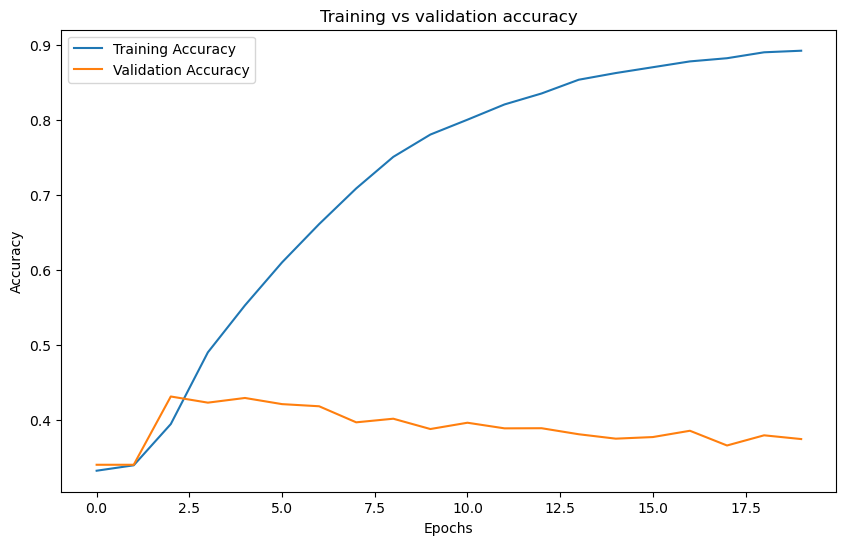

In [26]:
#Visualize the training values
plt.figure(figsize = (10, 6))
plt.plot(history.history["accuracy"], label = "Training Accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation Accuracy")
plt.title("Training vs validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

The results and the graph shows the model learned much better. Epoch 1 training = 34.30% validation 38.91% and the model reaches a training accuracy of 89.72% and validation accuracy of 38.12%. These shows improvement on the 13 class experiments.

### Introduce Callbacks

In [27]:
### Explain the code
from tensorflow.keras.callbacks import EarlyStopping

#Because we have an imbalanced class, 
#It is recommended using early stopping

early_stopping = EarlyStopping(
    monitor = "val_loss", 
    patience = 2, 
    restore_best_weights = True)

In [28]:
es_model = Sequential()

#Embedding layer: converts each integer word ID into a dense vector
#input dim:number of words in a vocabulary
#output dim:size of each word vector
es_model.add(Embedding(
    input_dim = max_words, output_dim = 128))

#LSTM Layer
#The LSTM processes the sequence of word embeddings
#and Learns relationships between the words
es_model.add(LSTM(64))

#Dropout
#Randomly disables 30% of the neurons during training
#this helps reduce overfitting
es_model.add(Dropout(0.5))

#Output layer
#There are 13 emotion classes
#softmax produces a probability for each class
es_model.add(Dense(len(label_encoder.classes_), activation = "softmax"))

In [29]:
es_model.compile(optimizer = "adam", 
              loss = "sparse_categorical_crossentropy", 
              metrics = ["accuracy"])

In [30]:
es_history = es_model.fit(
    x_train, y_train, 
    validation_data = (x_val, y_val), 
    epochs = 20, 
    batch_size = 64, 
    callbacks = [early_stopping]
)

Epoch 1/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.3364 - loss: 1.6295 - val_accuracy: 0.3405 - val_loss: 1.6094
Epoch 2/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.3781 - loss: 1.5367 - val_accuracy: 0.4059 - val_loss: 1.4766
Epoch 3/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.4620 - loss: 1.3852 - val_accuracy: 0.4354 - val_loss: 1.4758
Epoch 4/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.5280 - loss: 1.2574 - val_accuracy: 0.4293 - val_loss: 1.4727
Epoch 5/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.5847 - loss: 1.1427 - val_accuracy: 0.4341 - val_loss: 1.6215
Epoch 6/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.6351 - loss: 1.0258 - val_accuracy: 0.4254 - val_loss: 1.6727


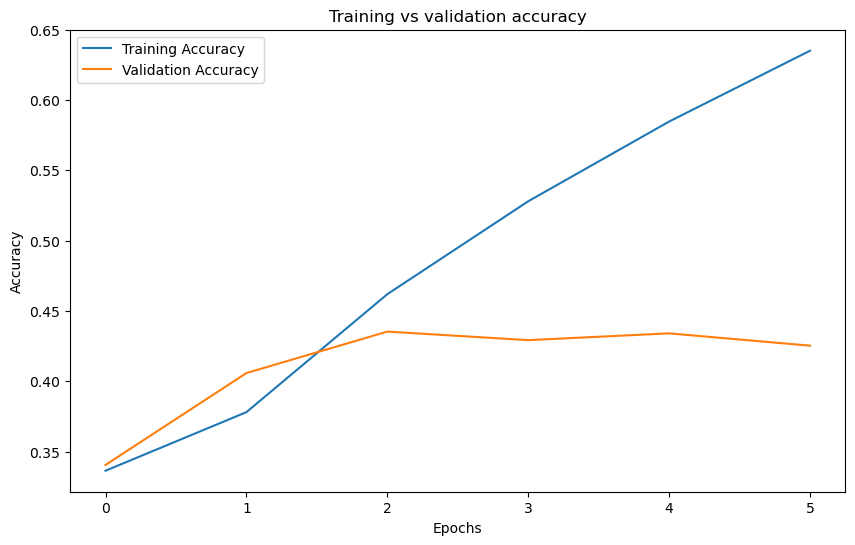

In [31]:
plt.figure(figsize = (10, 6))
plt.plot(es_history.history["accuracy"], label = "Training Accuracy")
plt.plot(es_history.history["val_accuracy"], label = "Validation Accuracy")
plt.title("Training vs validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Metrics

In [32]:
y_probability = es_model.predict(x_test)

#Select the class with the hightest probability
y_pred = np.argmax(y_probability, axis = 1)

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [33]:
cm = confusion_matrix(
    y_test,
    y_pred
)

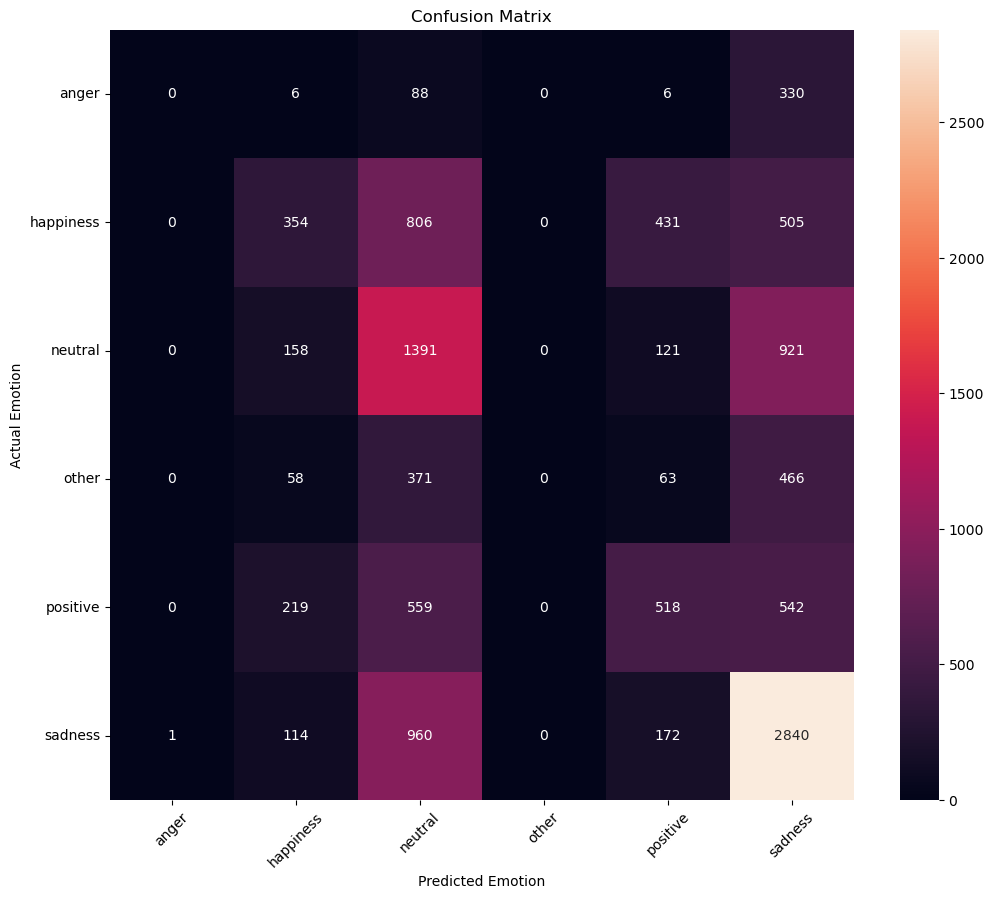

In [34]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

### GRU

In [35]:
from tensorflow.keras.layers import GRU

In [36]:
gru_model = Sequential()

#Embedding layer: converts each integer word ID into a dense vector
#input dim:number of words in a vocabulary
#output dim:size of each word vector
gru_model.add(Embedding(
    input_dim = max_words, output_dim = 128))

#LSTM Layer
#The LSTM processes the sequence of word embeddings
#and Learns relationships between the words
gru_model.add(GRU(128))

#Dropout
#Randomly disables 30% of the neurons during training
#this helps reduce overfitting
gru_model.add(Dropout(0.5))

#Output layer
#There are 13 emotion classes
#softmax produces a probability for each class
gru_model.add(Dense(len(label_encoder.classes_), activation = "softmax"))

In [37]:
gru_model.compile(optimizer = "adam", 
              loss = "sparse_categorical_crossentropy", 
              metrics = ["accuracy"])

In [38]:
#GRU with callback

gru_history = gru_model.fit(
    x_train, y_train, 
    validation_data = (x_val, y_val), 
    epochs = 20, 
    batch_size = 64, 
    callbacks = [early_stopping]
)

Epoch 1/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.3356 - loss: 1.6251 - val_accuracy: 0.3405 - val_loss: 1.6132
Epoch 2/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - accuracy: 0.3462 - loss: 1.6062 - val_accuracy: 0.4004 - val_loss: 1.5105


### Simple RNN

### Bi-LSTM

In [40]:
from tensorflow.keras.layers import Bidirectional

In [42]:
bilstm_model = Sequential()

#Embedding layer: converts each integer word ID into a dense vector
#input dim:number of words in a vocabulary
#output dim:size of each word vector
bilstm_model.add(Embedding(
    input_dim = max_words, output_dim = 128))

#LSTM Layer
#The LSTM processes the sequence of word embeddings
#and Learns relationships between the words
bilstm_model.add(Bidirectional(LSTM(128)))

#Dropout
#Randomly disables 30% of the neurons during training
#this helps reduce overfitting
bilstm_model.add(Dropout(0.5))

#Output layer
#There are 13 emotion classes
#softmax produces a probability for each class
bilstm_model.add(Dense(len(label_encoder.classes_), activation = "softmax"))

In [43]:
bilstm_model.compile(optimizer = "adam", 
              loss = "sparse_categorical_crossentropy", 
              metrics = ["accuracy"])

In [44]:
bilstm_history = bilstm_model.fit(
    x_train, y_train, 
    validation_data = (x_val, y_val), 
    epochs = 20, 
    batch_size = 64, 
    callbacks = [early_stopping]
)

Epoch 1/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 22s 57ms/step - accuracy: 0.4048 - loss: 1.5124 - val_accuracy: 0.4464 - val_loss: 1.4251
Epoch 2/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - accuracy: 0.5176 - loss: 1.2905 - val_accuracy: 0.4563 - val_loss: 1.4185
Epoch 3/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 22s 61ms/step - accuracy: 0.6104 - loss: 1.0699 - val_accuracy: 0.4441 - val_loss: 1.5299
Epoch 4/20
350/350 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.6984 - loss: 0.8568 - val_accuracy: 0.4184 - val_loss: 1.6919


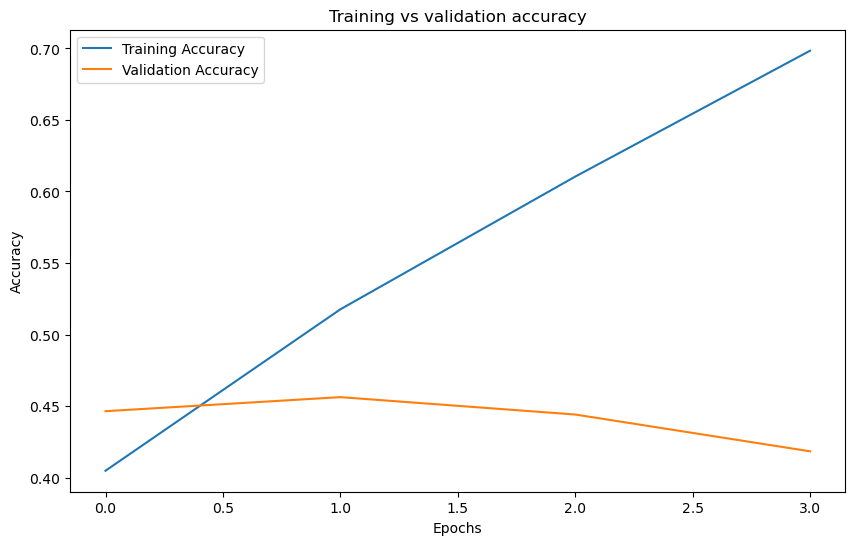

In [45]:
plt.figure(figsize = (10, 6))
plt.plot(bilstm_history.history["accuracy"], label = "Training Accuracy")
plt.plot(bilstm_history.history["val_accuracy"], label = "Validation Accuracy")
plt.title("Training vs validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()